# Pass 12

## Problem Definition


Business problem: estimate a house’s sale price.

Data science problem: supervised regression, since we know the real prices and the target is a number.

## Data Collection/Sources


In [1]:
#import from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load all the data
house_df= pd.read_csv(url)


In [4]:
# find all number columns (int and float)
num_columns = house_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_columns

['PID',
 'MS SubClass',
 'Lot Frontage',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

In [5]:
# Drop ID columns: they're labels, not real measurements
id_columns = ['Order', 'PID']

In [6]:
# this now includes int AND float columns
house_df_target_floats = house_df[num_columns].drop(columns=id_columns, errors='ignore').copy()

In [7]:
# Columns data types
house_df_target_floats.dtypes.sort_values()


,0
MS SubClass,int64
Mo Sold,int64
Misc Val,int64
Pool Area,int64
Screen Porch,int64
3Ssn Porch,int64
Enclosed Porch,int64
Open Porch SF,int64
Wood Deck SF,int64
Fireplaces,int64


In [8]:
# look at first and last few rows
house_df_target_floats.head()


,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,0,0,0,0,0,0,0,7,2007,115400
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,280,184,0,0,0,0,0,4,2010,254000
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,256,0,0,0,0,0,0,4,2009,155000


In [9]:
# look at the last few rows
house_df_target_floats.tail()

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000
2636,60,41.0,12460,7,5,1999,2000,0.0,870.0,0.0,...,144,44,0,0,0,0,0,5,2008,225000


In [10]:
# look at shape and size

print(house_df_target_floats.shape)
print(house_df_target_floats.size)


(2637, 37)
97569


In [11]:
# display meta data (info)
house_df_target_floats.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 37 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2637 non-null   int64  
 1   Lot Frontage     2188 non-null   float64
 2   Lot Area         2637 non-null   int64  
 3   Overall Qual     2637 non-null   int64  
 4   Overall Cond     2637 non-null   int64  
 5   Year Built       2637 non-null   int64  
 6   Year Remod/Add   2637 non-null   int64  
 7   Mas Vnr Area     2614 non-null   float64
 8   BsmtFin SF 1     2636 non-null   float64
 9   BsmtFin SF 2     2636 non-null   float64
 10  Bsmt Unf SF      2636 non-null   float64
 11  Total Bsmt SF    2636 non-null   float64
 12  1st Flr SF       2637 non-null   int64  
 13  2nd Flr SF       2637 non-null   int64  
 14  Low Qual Fin SF  2637 non-null   int64  
 15  Gr Liv Area      2637 non-null   int64  
 16  Bsmt Full Bath   2635 non-null   float64
 17  Bsmt Half Bath

In [12]:
# display summary statistics
house_df_target_floats.describe()



,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2637.000000,2188.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2614.000000,2636.000000,2636.000000,...,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000
mean,57.349261,69.166819,10044.694729,6.097459,5.569966,1971.288586,1984.202882,101.887911,438.441199,51.068665,...,94.305271,46.984452,22.813424,2.368601,15.775123,2.130072,42.014031,6.243838,2007.795601,179986.230186
std,42.499091,23.356779,6742.549521,1.411522,1.118262,30.306986,20.913077,179.578232,449.602326,172.521803,...,126.927272,66.564333,61.177638,23.160600,55.783751,35.140140,393.158781,2.722093,1.306403,78309.251522
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,20.000000,58.000000,7436.000000,5.000000,5.000000,1954.000000,1965.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,50.000000,68.000000,9450.000000,6.000000,5.000000,1973.000000,1993.000000,0.000000,368.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,70.000000,80.000000,11526.000000,7.000000,6.000000,2001.000000,2004.000000,164.000000,732.000000,0.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213000.000000
max,190.000000,313.000000,164660.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1526.000000,...,1424.000000,742.000000,584.000000,407.000000,576.000000,800.000000,12500.000000,12.000000,2010.000000,745000.000000


In [13]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [14]:
# look for nulls in target and features
house_df_target_floats.isnull().sum().sort_values(ascending=False)

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2
Garage Cars,1
Garage Area,1
Bsmt Unf SF,1
BsmtFin SF 1,1
Total Bsmt SF,1


## Data Cleaning


### Backup 1

In [15]:
# make backup
house_df_target_floats_backup = house_df_target_floats.copy()

In [16]:
# restore from backup
house_df_target_floats = house_df_target_floats_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [17]:
# look for nulls in feature in percentage
house_df_target_floats.isnull().mean() * 100

,0
MS SubClass,0.000000
Lot Frontage,17.026925
Lot Area,0.000000
Overall Qual,0.000000
Overall Cond,0.000000
Year Built,0.000000
Year Remod/Add,0.000000
Mas Vnr Area,0.872203
BsmtFin SF 1,0.037922
BsmtFin SF 2,0.037922


### Impute

In [18]:
# Calculate the median
median_frontage = house_df_target_floats['Lot Frontage'].median()
median_garage_yr = house_df_target_floats['Garage Yr Blt'].median()

print(median_frontage)
print(median_garage_yr)

# Fill nulls with the median
house_df_target_floats['Lot Frontage']= house_df_target_floats['Lot Frontage'].fillna(median_frontage)
house_df_target_floats['Garage Yr Blt']= house_df_target_floats['Garage Yr Blt'].fillna(median_garage_yr)

#verify there are no nulls
house_df_target_floats.isnull().sum()


68.0
1979.0


,0
MS SubClass,0
Lot Frontage,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
Mas Vnr Area,23
BsmtFin SF 1,1
BsmtFin SF 2,1


In [19]:
print(house_df_target_floats['Lot Frontage'].median())
print(house_df_target_floats['Garage Yr Blt'].median())

68.0
1979.0


In [20]:
house_df_target_floats.isnull().sum() * 100000

,0
MS SubClass,0
Lot Frontage,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
Mas Vnr Area,2300000
BsmtFin SF 1,100000
BsmtFin SF 2,100000


In [21]:
# drop the nulls values in features
house_df_target_floats = house_df_target_floats.dropna(subset=['Mas Vnr Area',
'BsmtFin SF 1',
'BsmtFin SF 2',
'Bsmt Unf SF',
'Total Bsmt SF',
'Bsmt Full Bath',
'Garage Cars',
'Garage Area',
'Bsmt Half Bath'])

In [22]:
#check that null are removed from features
house_df_target_floats.isnull().sum()

,0
MS SubClass,0
Lot Frontage,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
Mas Vnr Area,0
BsmtFin SF 1,0
BsmtFin SF 2,0


## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

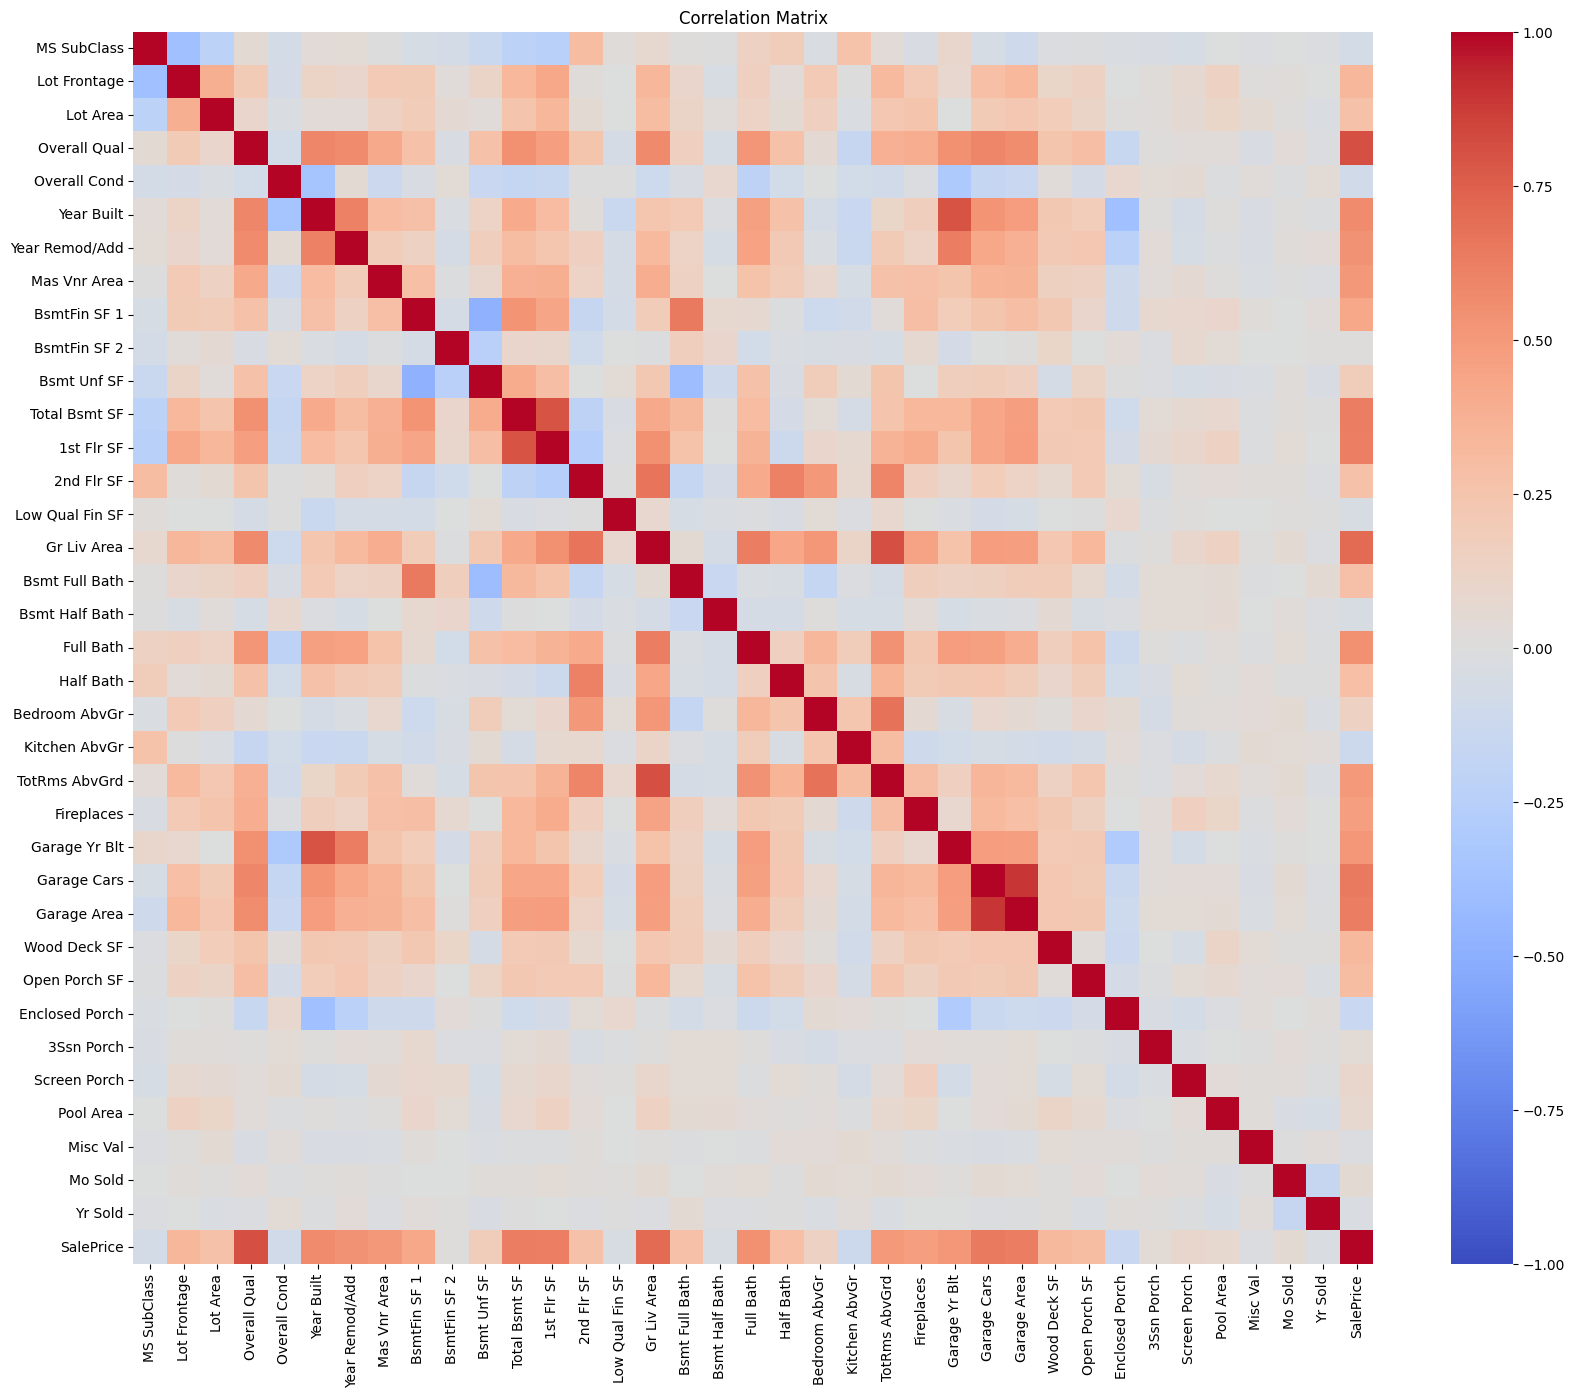

In [23]:
# Calculate & display correlation matrix, check if features correlated with target
plt.figure(figsize=(20, 16))
sns.heatmap(house_df_target_floats.corr(),
            annot=False,
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [24]:
# Calculate a correlation matrix for features & features
features_df = house_df_target_floats.drop(columns=['SalePrice'])
features_corr = features_df.corr()

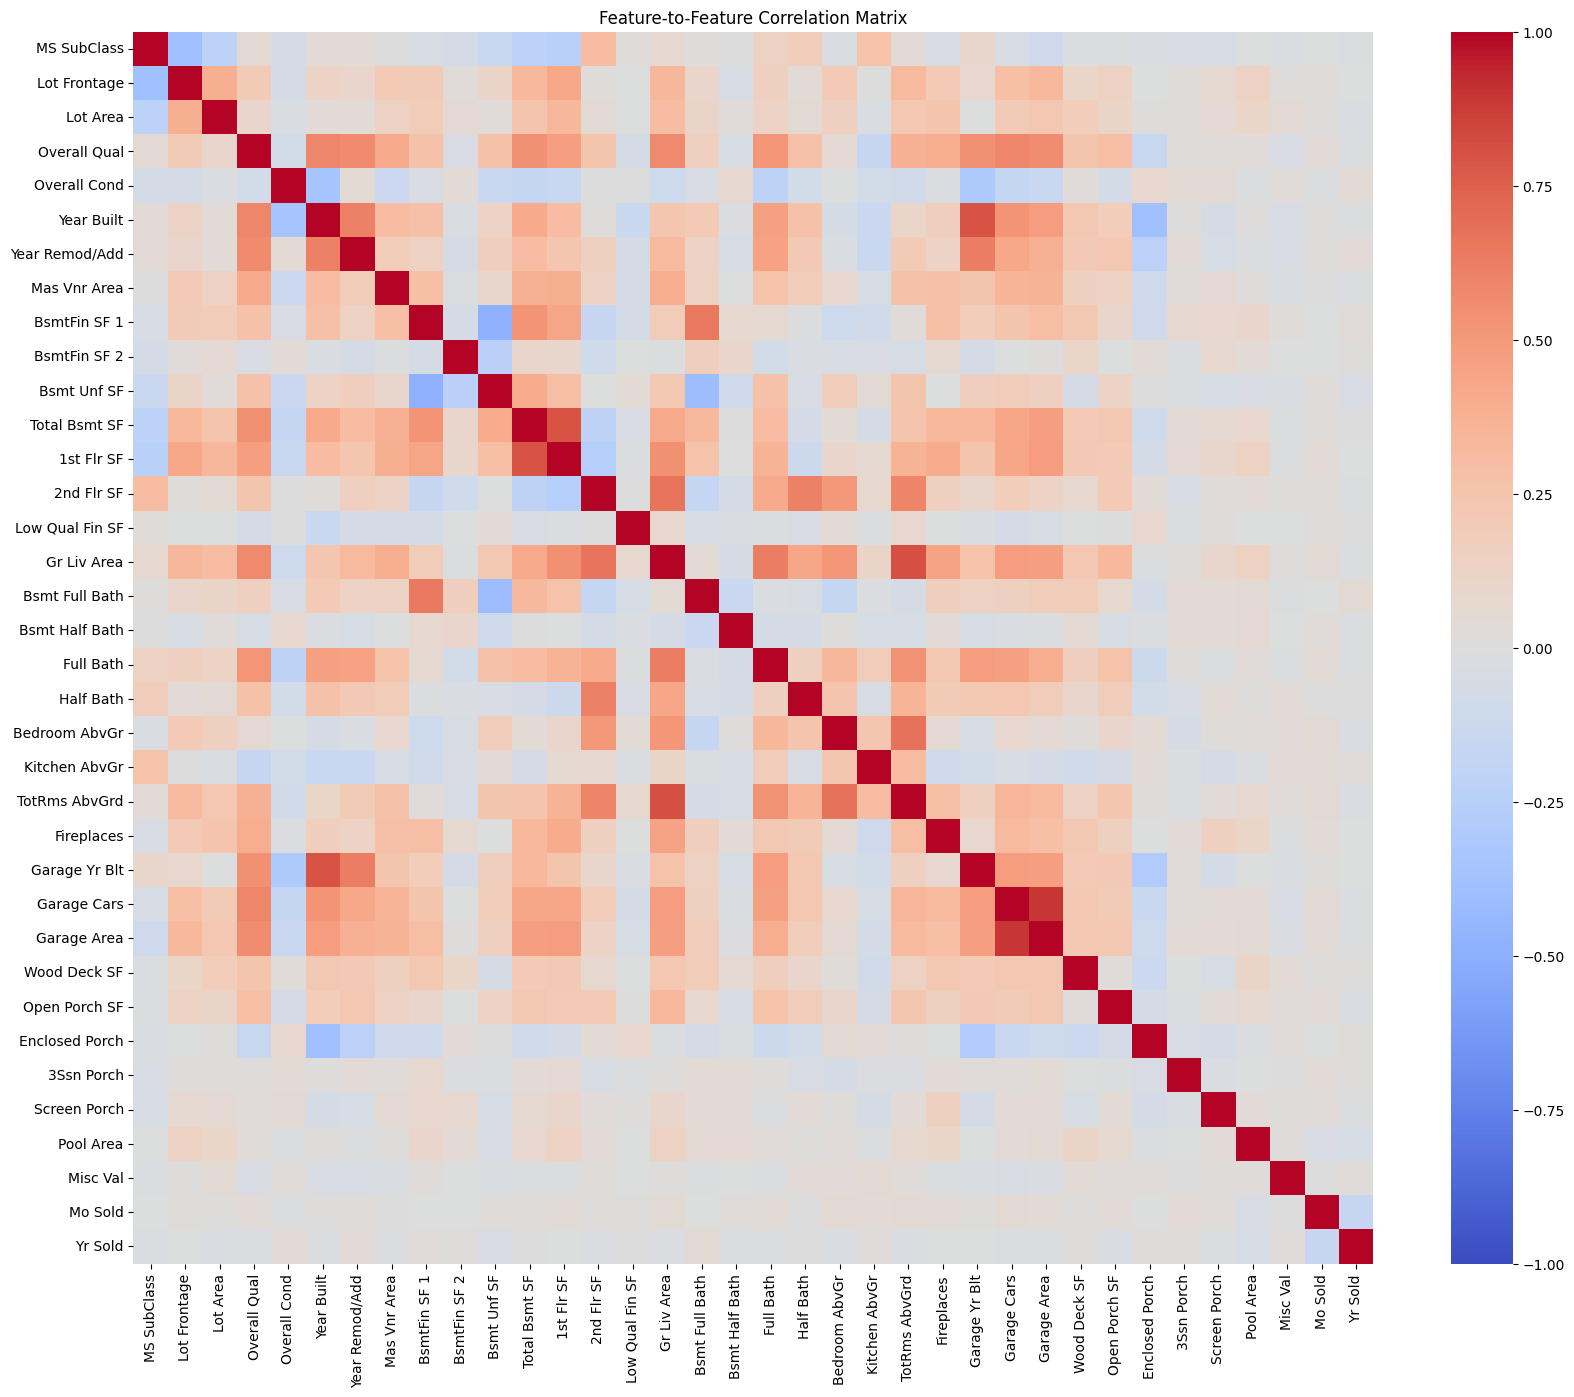

In [25]:
# Display the matrix, check if features are correlated with each other
plt.figure(figsize=(20, 16))
sns.heatmap(features_corr,
            annot=False,
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Feature-to-Feature Correlation Matrix')
plt.show()

## Processing



### Fit & Assess model- Using Ridge Regression

In [26]:
# break data into training and testing sets
X = house_df_target_floats.drop(columns=['SalePrice'])
y = house_df_target_floats['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

In [27]:
# Repeat CV - Ridge with ALL float features
n = 500
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    model = Ridge(alpha=1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[i] = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Repeat CV RMSE (all features): {results.mean().round(2)}")
print(f"Number of features: {X.shape[1]}")

Repeat CV RMSE (all features): 32928.38
Number of features: 36


In [28]:
# Fit Ridge once on scaled data to see each feature's coefficient
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
model = Ridge(alpha=1)
model.fit(X_train_s, y_train)

coef_df = pd.DataFrame({'Feature': X.columns, 'Ridge': model.coef_})
coef_df['Abs'] = coef_df['Ridge'].abs()
coef_df.sort_values('Abs', ascending=False)

,Feature,Ridge,Abs
3,Overall Qual,22874.872481,22874.872481
15,Gr Liv Area,16079.978702,16079.978702
13,2nd Flr SF,10660.584976,10660.584976
8,BsmtFin SF 1,9188.322545,9188.322545
11,Total Bsmt SF,9059.273550,9059.273550
20,Bedroom AbvGr,-8862.559594,8862.559594
12,1st Flr SF,8652.030836,8652.030836
5,Year Built,6786.331010,6786.331010
7,Mas Vnr Area,5271.263940,5271.263940
22,TotRms AbvGrd,4832.712031,4832.712031


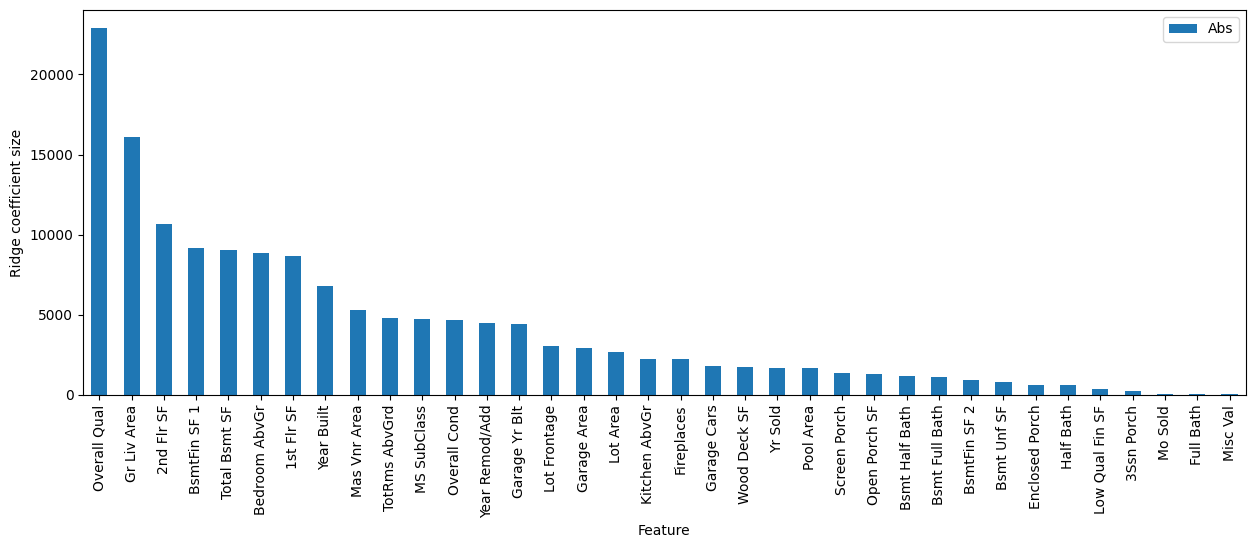

In [29]:
# Bar graph of feature importance
coef_df.sort_values('Abs', ascending=False).plot(x='Feature', y='Abs', kind='bar', figsize=(15,5))
plt.ylabel('Ridge coefficient size');

In [30]:
# Look at the bar graph, then set the cutoff in the gap between tall and short bars
cutoff = 5000
selected = coef_df[coef_df['Abs'] > cutoff]['Feature'].tolist()
selected

['Overall Qual',
 'Year Built',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Gr Liv Area',
 'Bedroom AbvGr']

In [31]:
# Repeat CV - Ridge with SELECTED features
X_sel = X[selected]
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.25)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    model = Ridge(alpha=1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[i] = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Repeat CV RMSE (selected features): {results.mean().round(2)}")
print(f"Number of features: {len(selected)}")

Repeat CV RMSE (selected features): 33941.51
Number of features: 9


In [32]:
# Final fit on selected features, fixed split
X_train, X_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.2, random_state=4)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = Ridge(alpha=1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

[(270000, np.float64(309372.88798243913)),
 (255000, np.float64(255719.3730648121)),
 (149900, np.float64(169563.30914680654)),
 (260000, np.float64(274848.4837283713)),
 (143750, np.float64(158155.74829372216)),
 (115000, np.float64(118786.80929874221)),
 (140000, np.float64(154376.12596215)),
 (213750, np.float64(232188.8736375776)),
 (173000, np.float64(158057.36792814196)),
 (124500, np.float64(113959.7345373577))]

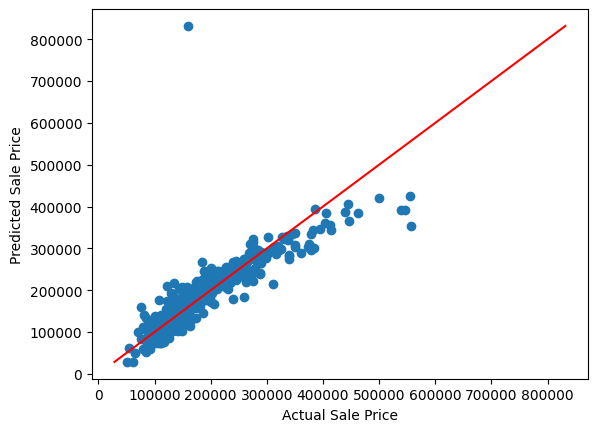

In [33]:
# See how well the model does compare to the test data

plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)], [min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price');

list(zip(y_test, y_pred))[:10]

In [34]:
# RMS on test data
rmse = mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse} ")

#RMSE- shows the amount the model was wrong

RMSE: 41995.34265058627 


## Residual Analysis

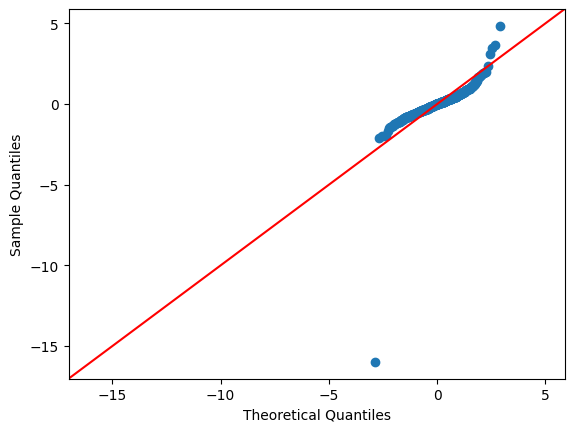

In [35]:
# QQ Plot - Checks if residuals(misses)are normally distributed (bell-shaped)
# res= real price- guess. Positive= guessed to low. Negative= guesses to high
# fit=True, converts model misses from dollars into standard units
# line="45" draws a line where "should be" = "actually is
# Read it: dots on red line= normal. Ends curving away= not normal


res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

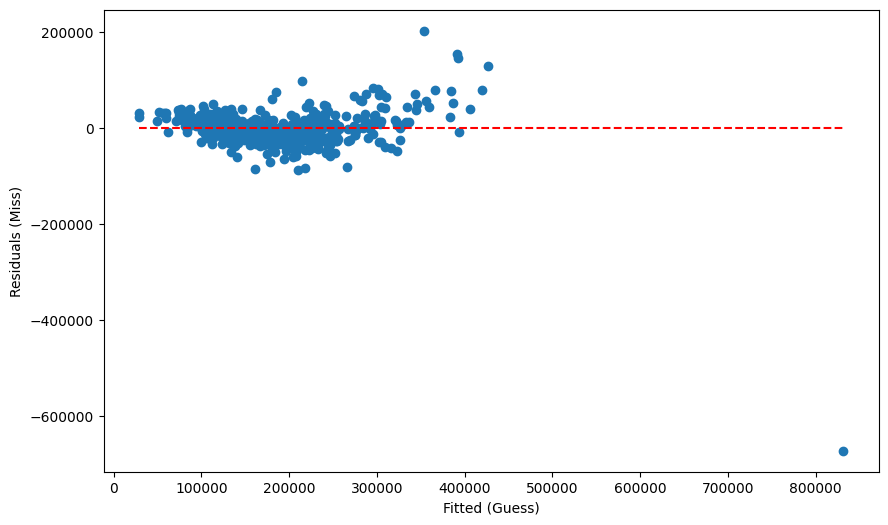

In [36]:
# Residuals vs Fitted (Predicted) Values - Constant variance

plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted (Guess)")
plt.ylabel("Residuals (Miss)")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;



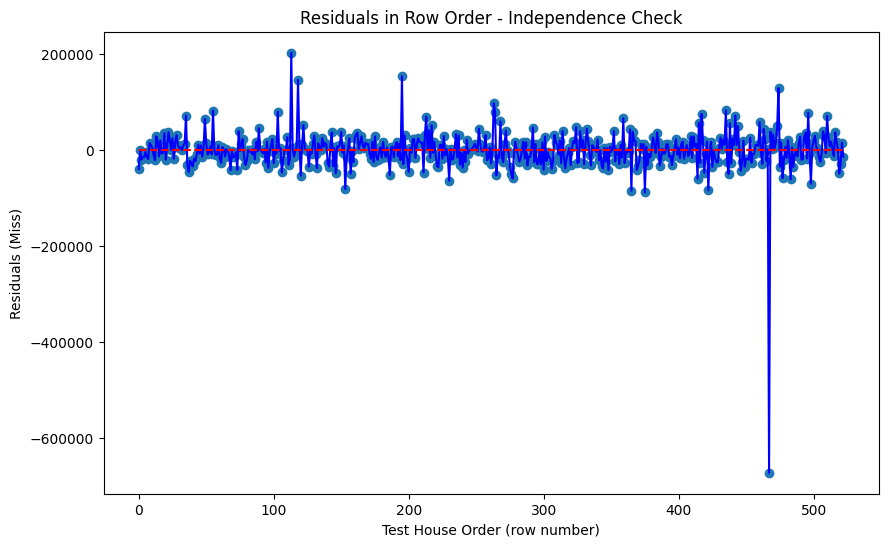

In [37]:
# Residuals vs Time - checks indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Test House Order (row number)")
plt.ylabel("Residuals (Miss)")
plt.title("Residuals in Row Order - Independence Check")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

# (does one miss tell you anything about the next miss? It shouldn't.)
# Across = house's row number (0, 1, 2...). Up = miss. Blue line connects them in order.
# Good = random zigzag around 0. Bad = waves, trends, or long runs on one side.



## Data Visualization/Communication of Results
